# Самостоятельная работа на 2 недели  
## CasADi + IPOPT: задача оптимального управления как NLP

До этого вы решали задачи ОУ через собственный градиент, метод проекции и `L-BFGS-B`.

В этой работе будет другой подход. Состояния в узлах сетки и управления становятся переменными конечномерной задачи оптимизации, а дискретная динамика задаётся ограничениями.

Для решения используем:

- **CasADi** — строит символьные выражения и производные;
- **IPOPT** — решает нелинейную задачу оптимизации;
- **Opti** — удобный интерфейс CasADi для записи переменных, функционала и ограничений.

Работа рассчитана на две недели. Первую неделю лучше закончить на двойном интеграторе. Во вторую перейти к маятнику, RK4 и индивидуальному варианту.

## 0. Установка

Проверьте импорт:

In [19]:
%pip install casadi

Note: you may need to restart the kernel to use updated packages.


In [20]:
import casadi as ca

print("CasADi version:", ca.__version__)

CasADi version: 3.8.2


Если появилась ошибка `ModuleNotFoundError`, выполните в отдельной ячейке

```python
%pip install casadi
```

после установки сделайте `Kernel → Restart Kernel` и снова запустите notebook.

Отдельно ставить IPOPT обычно не требуется: он входит в стандартную Python-установку CasADi.

Официальная документация:

- https://web.casadi.org/docs/
- https://web.casadi.org/get/

### Проверка IPOPT

Эта ячейка должна вывести число, близкое к 1.

In [21]:
opti = ca.Opti()

z = opti.variable()
opti.minimize((z - 1)**2)

opti.solver(
    "ipopt",
    {"print_time": False},
    {"print_level": 0, "sb": "yes"},
)

sol = opti.solve()

print(sol.value(z))

1.0


# Неделя 1

## 1. Что в CasADi отличается от NumPy

В NumPy выражение обычно сразу вычисляется. В CasADi можно сначала построить символьное выражение, а потом превратить его в функцию.

In [22]:
x = ca.MX.sym("x")

f = ca.sin(x) + x**2
df = ca.jacobian(f, x)

F = ca.Function(
    "F",
    [x],
    [f, df],
    ["x"],
    ["f", "df"],
)

print(F(2.0))

(DM(4.9093), DM(3.58385))


Здесь `MX` хранит не число, а выражение. `ca.jacobian` строит производную автоматически.

### Небольшое задание

Замените
$$
f(x)=\sin x+x^2
$$
на
$$
f(x)=e^{-x^2}\cos x
$$
и проверьте производную в точке $x=1$.

In [28]:
# Ваш код
import math

x = ca.MX.sym("x")

f = ca.exp(-x**2) * ca.cos(x)
df = ca.jacobian(f, x)

F = ca.Function(
    "F",
    [x],
    [f, df],
    ["x"],
    ["f", "df"],
)

f_val, df_val = F(1.0)
df_exact = -math.exp(-1) * (2 * math.cos(1) + math.sin(1))

print("f(1) =", f_val)
print("CasADi: f'(1) =", df_val)
print("Аналитически: f'(1) =", df_exact)
print("Ошибка =", abs(float(df_val) - df_exact))

f(1) = 0.198766
CasADi: f'(1) = -0.707092
Аналитически: f'(1) = -0.7070920963459382
Ошибка = 0.0


## 2. Первая задача через `Opti`

Решим
$$
\min_{x,y}(x-2)^2+(y-1)^2
$$
при
$$
x+y=2,\qquad x\ge0,\qquad y\ge0.
$$

In [24]:
opti = ca.Opti()

x = opti.variable()
y = opti.variable()

opti.minimize(
    (x - 2)**2 + (y - 1)**2
)

opti.subject_to(x + y == 2)
opti.subject_to(x >= 0)
opti.subject_to(y >= 0)

opti.solver(
    "ipopt",
    {"print_time": False},
    {"print_level": 0, "sb": "yes"},
)

sol = opti.solve()

print("x =", sol.value(x))
print("y =", sol.value(y))

x = 1.4999999991634128
y = 0.5000000008365874


Здесь уже виден основной шаблон:

```python
opti = ca.Opti()
x = opti.variable(...)
opti.minimize(...)
opti.subject_to(...)
opti.solver("ipopt")
sol = opti.solve()
```

После `solve()` численные значения переменных получаются через `sol.value(...)`.

### Проверьте самостоятельно

Замените ограничение $x+y=2$ на
$$
x+2y=2.
$$

Перед запуском прикиньте, в какую сторону должно сдвинуться решение.

<span style="color:red">Прогноз:</span>

при замене ограничения $x+y=2$ на $x+2y=2$ ожидается увеличение $x$ и уменьшение $y$

In [29]:
# Ваш код
opti = ca.Opti()

x = opti.variable()
y = opti.variable()

opti.minimize(
    (x - 2)**2 + (y - 1)**2
)

opti.subject_to(x + 2*y == 2)
opti.subject_to(x >= 0)
opti.subject_to(y >= 0)

opti.solver(
    "ipopt",
    {"print_time": False},
    {"print_level": 0, "sb": "yes"},
)

sol = opti.solve()

print("x =", sol.value(x))
print("y =", sol.value(y))

x = 1.5999999981052953
y = 0.2000000009473524


# 3. Двойной интегратор: direct transcription

Вернёмся к знакомой задаче:
$$
\dot x_1=x_2,\qquad \dot x_2=u,
$$
$$
x(0)=(0,0),\qquad T=2,\qquad |u|\le1.
$$

Функционал:
$$
J=
100(x_1(T)-1)^2+
20x_2(T)^2+
0.05\int_0^T u^2(t)\,dt.
$$

Берём кусочно-постоянное управление на $N$ интервалах. Для двойного интегратора точный шаг имеет вид
$$
x_{1,k+1}
=
x_{1,k}
+
h x_{2,k}
+
\frac{h^2}{2}u_k,
$$
$$
x_{2,k+1}
=
x_{2,k}
+
h u_k.
$$

В CasADi введём сразу все состояния
$$
X=(x_0,\ldots,x_N)
$$
и все управления
$$
U=(u_0,\ldots,u_{N-1})
$$
как переменные оптимизации.

Динамика станет системой равенств.

### Перед кодом

При $N=20$ посчитайте:

1. сколько скалярных переменных содержат `X` и `U` вместе;
2. сколько скалярных равенств дают начальное условие и динамика;
3. сколько степеней свободы остаётся после этих равенств.

Запишите ответ в Markdown-ячейке ниже.

### Ваш ответ


1. число скалярных переменных: $2(N+1)+N=62$
2. число равенств: $2+2N=42$
3. число степеней свободы: $62-42=20$

### Задание

Допишите функцию. Основные места помечены `TODO`.

In [30]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt


def solve_double_integrator(
    N=20,
    vmax=None,
):
    T = 2.0
    h = T / N

    opti = ca.Opti()

    X = opti.variable(2, N + 1)
    U = opti.variable(1, N)

    # Начальное условие
    opti.subject_to(X[:, 0] == ca.DM([0.0, 0.0]))

    for k in range(N):
        xk = X[:, k]
        uk = U[0, k]

        x_next = ca.vertcat(
            xk[0] + h * xk[1] + 0.5 * h**2 * uk,
            xk[1] + h * uk,
        )

        # Уравнения динамики
        opti.subject_to(X[:, k + 1] == x_next)

    # Ограничение на управление
    opti.subject_to(opti.bounded(-1, U, 1))

    if vmax is not None:
        # ограничение на скорость
        opti.subject_to(
            opti.bounded(
                -vmax,
                X[1, :],
                vmax,
            )
        )

    e = X[:, -1] - ca.DM([1.0, 0.0])

    # Функционал
    J = 100 * e[0]**2 + 20 * e[1]**2 + 0.05 * h * ca.sumsqr(U)

    opti.minimize(J)

    # Начальное приближение
    opti.set_initial(
        X[0, :],
        np.linspace(0, 1, N + 1),
    )
    opti.set_initial(X[1, :], 0)
    opti.set_initial(U, 0)

    opti.solver(
        "ipopt",
        {
            "expand": True,
            "print_time": False,
        },
        {
            "print_level": 0,
            "sb": "yes",
            "max_iter": 1000,
        },
    )

    sol = opti.solve()

    X_sol = np.array(sol.value(X))
    U_sol = np.array(sol.value(U)).reshape(-1)

    return {
        "X": X_sol,
        "U": U_sol,
        "J": float(sol.value(J)),
        "iterations": sol.stats()["iter_count"],
    }

После заполнения функция должна решать базовую задачу:

In [31]:
result = solve_double_integrator(N=20)

print("J =", result["J"])
print("x(T) =", result["X"][:, -1])
print("iterations =", result["iterations"])

J = 0.09001948529979364
x(T) = [0.99749513 0.01244658]
iterations = 12


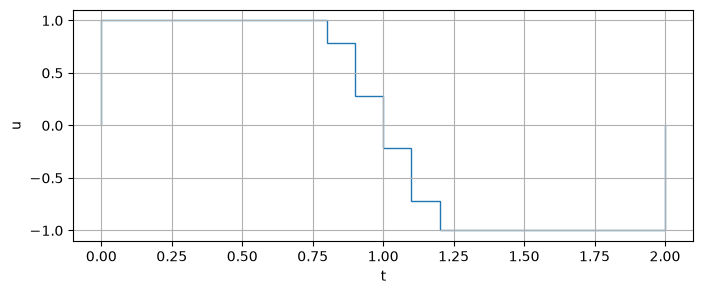

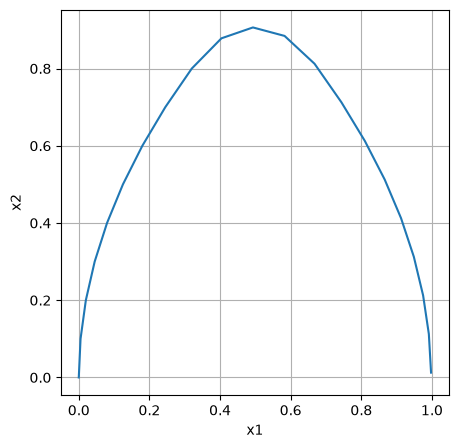

In [32]:
T = 2.0
N = len(result["U"])
t = np.linspace(0, T, N + 1)

plt.figure(figsize=(8, 3))
plt.stairs(result["U"], t)
plt.xlabel("t")
plt.ylabel("u")
plt.grid()
plt.show()

plt.figure(figsize=(5, 5))
plt.plot(
    result["X"][0],
    result["X"][1],
)
plt.xlabel("x1")
plt.ylabel("x2")
plt.grid()
plt.show()

### Контрольный ориентир

Для $N=20$ должно получиться значение
$$
J\approx0.09.
$$

Если получается число другого порядка, сначала проверьте динамические ограничения и множитель $h$ в интегральной части функционала.

## 4. Ограничение на состояние

Добавим
$$
|x_2(t)|\le0.8.
$$

В direct transcription состояния уже являются переменными задачи, поэтому ограничение добавляется непосредственно на `X[1, :]`.

Запустите:

In [33]:
result_v = solve_double_integrator(
    N=20,
    vmax=0.8,
)

print("J =", result_v["J"])
print("x(T) =", result_v["X"][:, -1])
print(
    "max |x2| =",
    np.max(np.abs(result_v["X"][1])),
)

J = 0.1187948462968286
x(T) = [0.98980455 0.03973945]
max |x2| = 0.7999999943776933


Сравните решения с ограничением и без него:

- $J$;
- конечное состояние;
- $u(t)$;
- $x_2(t)$.

Напишите 3–4 предложения: как новое ограничение изменило решение и почему в direct transcription его удобно добавлять.

Без ограничения:
J = 0.09001948529979364
x(T) = [0.99749513 0.01244658]
max |x2| = 0.9064179219069441

С ограничением:
J = 0.1187948462968286
x(T) = [0.98980455 0.03973945]
max |x2| = 0.7999999943776933


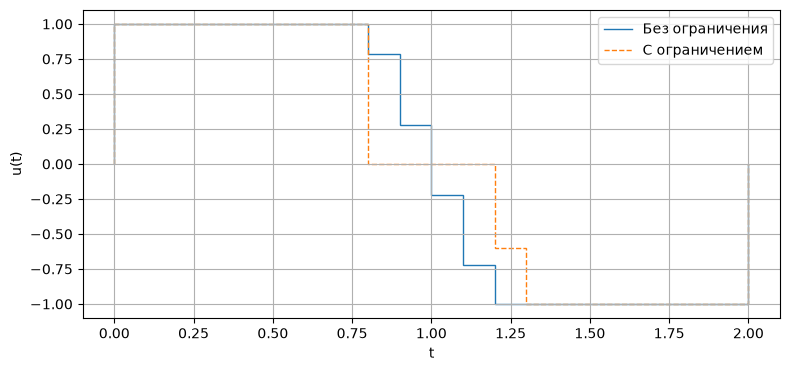

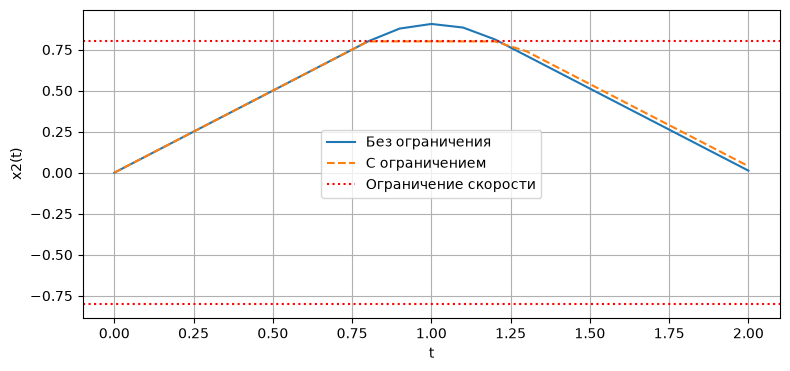

In [34]:
# Ваше сравнение и графики
t = np.linspace(0, 2, 21)

print("Без ограничения:")
print("J =", result["J"])
print("x(T) =", result["X"][:, -1])
print("max |x2| =", np.max(np.abs(result["X"][1])))

print("\nС ограничением:")
print("J =", result_v["J"])
print("x(T) =", result_v["X"][:, -1])
print("max |x2| =", np.max(np.abs(result_v["X"][1])))

plt.figure(figsize=(9, 4))

plt.stairs(result["U"], t, label="Без ограничения")
plt.stairs(result_v["U"], t, linestyle="--", label="С ограничением")

plt.xlabel("t")
plt.ylabel("u(t)")
plt.grid()
plt.legend()
plt.show()

plt.figure(figsize=(9, 4))

plt.plot(t, result["X"][1], label="Без ограничения")
plt.plot(t, result_v["X"][1], "--", label="С ограничением")
plt.axhline(0.8, color="red", linestyle=":", label="Ограничение скорости")
plt.axhline(-0.8, color="red", linestyle=":")

plt.xlabel("t")
plt.ylabel("x2(t)")
plt.grid()
plt.legend()
plt.show()

<span style="color:red">Вывод:</span>

1. добавление ограничения $|x_2(t)| \leq 0.8$ увеличило значение функционала с $0.0900$ до $0.1188$
2. конечное состояние изменилось с $(0.9975,\ 0.0124)$ на $(0.9898,\ 0.0397)$, то есть отклонение от целевого состояния увеличилось
3. управление приобрело участок $u=0$, на котором скорость удерживается на уровне $0.8$, тогда как без ограничения максимальная скорость достигала $0.9064$
4. в методе direct transcription ограничения на состояния удобно добавлять непосредственно к переменным оптимизации, поскольку состояния уже включены в дискретную задачу

# Неделя 2

## 5. Нелинейный маятник

Теперь используем
$$
\dot\theta=\omega,
$$
$$
\dot\omega=-\sin\theta+u,
$$
$$
(\theta(0),\omega(0))=(0,0),
$$
$$
(\theta(T),\omega(T))\approx(\pi,0),
$$
$$
|u|\le2.
$$

Функционал:
$$
J=
20(\theta(T)-\pi)^2+
5\omega(T)^2+
0.05\int_0^T u^2(t)\,dt.
$$

Это та же постановка, которая использовалась в `sem5`, но теперь градиент вручную писать не нужно. CasADi построит необходимые производные для IPOPT.

### Два шага интегрирования

Euler:
$$
x_{k+1}=x_k+h f(x_k,u_k).
$$

RK4:
$$
\begin{aligned}
k_1 &= f(x_k,u_k),\\
k_2 &= f(x_k+\tfrac h2 k_1,u_k),\\
k_3 &= f(x_k+\tfrac h2 k_2,u_k),\\
k_4 &= f(x_k+h k_3,u_k),\\
x_{k+1} &= x_k+\frac h6(k_1+2k_2+2k_3+k_4).
\end{aligned}
$$

In [35]:
def pendulum_rhs(x, u):
    return ca.vertcat(
        x[1],
        -ca.sin(x[0]) + u,
    )


def euler_step(x, u, h):
    return x + h * pendulum_rhs(x, u)


def rk4_step(x, u, h):
    k1 = pendulum_rhs(x, u)
    k2 = pendulum_rhs(
        x + 0.5 * h * k1,
        u,
    )
    k3 = pendulum_rhs(
        x + 0.5 * h * k2,
        u,
    )
    k4 = pendulum_rhs(
        x + h * k3,
        u,
    )

    return (
        x
        + h / 6
        * (k1 + 2 * k2 + 2 * k3 + k4)
    )

### Задание

Допишите функцию `solve_pendulum`.

Параметр `method` принимает `"euler"` или `"rk4"`.

Пока используйте мягкий терминальный штраф, как в `sem5`.

In [36]:
def solve_pendulum(
    N=40,
    method="euler",
    omega_max=None,
    du_max=None,
    hard_terminal=False,
):
    T = 5.0
    h = T / N
    u_max = 2.0
    lam = 0.05

    opti = ca.Opti()

    X = opti.variable(2, N + 1)
    U = opti.variable(1, N)

    # Начальное условие
    opti.subject_to(X[:, 0] == ca.DM([0.0, 0.0]))

    # Ограничение на управление
    opti.subject_to(opti.bounded(-u_max, U, u_max))

    for k in range(N):
        xk = X[:, k]
        uk = U[0, k]

        if method == "euler":
            x_next = euler_step(xk, uk, h)
        elif method == "rk4":
            x_next = rk4_step(xk, uk, h)
        else:
            raise ValueError(
                "method must be 'euler' or 'rk4'"
            )

        # Динамическое ограничение
        opti.subject_to(X[:, k + 1] == x_next)

    if omega_max is not None:
        opti.subject_to(
            opti.bounded(
                -omega_max,
                X[1, :],
                omega_max,
            )
        )

    if du_max is not None:
        opti.subject_to(
            opti.bounded(
                -du_max,
                U[:, 1:] - U[:, :-1],
                du_max,
            )
        )

    e = X[:, -1] - ca.DM([np.pi, 0.0])

    if hard_terminal:
        opti.subject_to(
            X[:, -1]
            == ca.DM([np.pi, 0.0])
        )
        J = lam * h * ca.sumsqr(U)
    else:
        # Терминальный штраф + энергия управления
        J = (
            20 * e[0]**2
            + 5 * e[1]**2
            + lam * h * ca.sumsqr(U)
        )

    opti.minimize(J)

    opti.set_initial(
        X[0, :],
        np.linspace(0, np.pi, N + 1),
    )
    opti.set_initial(X[1, :], 0)
    opti.set_initial(U, 0)

    opti.solver(
        "ipopt",
        {
            "expand": True,
            "print_time": False,
        },
        {
            "print_level": 0,
            "sb": "yes",
            "max_iter": 1000,
        },
    )

    sol = opti.solve()

    return {
        "X": np.array(sol.value(X)),
        "U": np.array(
            sol.value(U)
        ).reshape(-1),
        "J": float(sol.value(J)),
        "iterations": sol.stats()["iter_count"],
    }

Сначала решите одну задачу:

In [37]:
pend_euler = solve_pendulum(
    N=40,
    method="euler",
)

print("J =", pend_euler["J"])
print(
    "x(T) =",
    pend_euler["X"][:, -1],
)

J = 0.10962537341786575
x(T) = [3.14011103 0.00477331]


Если решение получено, повторите для `method="rk4"` и сравните управления.

Euler:
J = 0.10962537341786575
x(T) = [3.14011103 0.00477331]

RK4:
J = 0.1211209207923147
x(T) = [3.13993904 0.00562456]

max |u_euler - u_rk4| = 0.055324955244385965


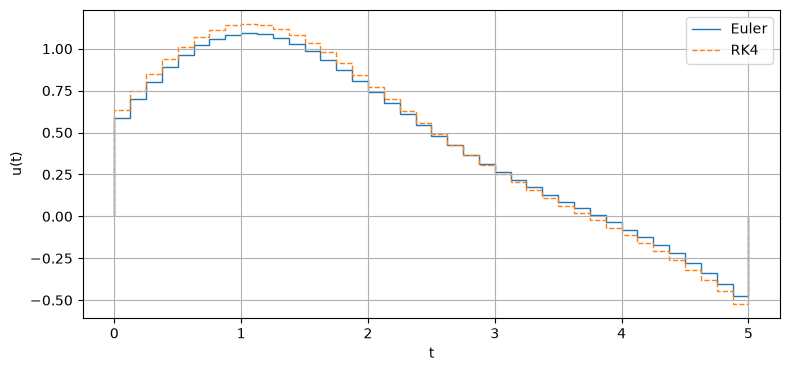

In [38]:
# Ваш код
pend_rk4 = solve_pendulum(N=40, method="rk4")

print("Euler:")
print("J =", pend_euler["J"])
print("x(T) =", pend_euler["X"][:, -1])

print("\nRK4:")
print("J =", pend_rk4["J"])
print("x(T) =", pend_rk4["X"][:, -1])

print("\nmax |u_euler - u_rk4| =",
      np.max(np.abs(pend_euler["U"] - pend_rk4["U"])))

t = np.linspace(0, 5, 41)

plt.figure(figsize=(9, 4))
plt.stairs(pend_euler["U"], t, label="Euler")
plt.stairs(pend_rk4["U"], t, linestyle="--", label="RK4")

plt.xlabel("t")
plt.ylabel("u(t)")
plt.grid()
plt.legend()
plt.show()

<span style="color:red">Вывод:</span>

1. оба метода успешно решили задачу, конечные состояния близки к целевому $(\pi, 0)$
2. значения функционала составили $J_{\text{Euler}}\approx 0.1096$ и $J_{\text{RK4}}\approx 0.1211$
3. оптимальные управления имеют схожую форму, максимальное абсолютное различие составляет около $0.0553$
4. различия обусловлены использованием разных схем интегрирования, при этом меньшее значение функционала не обязательно означает более высокую точность

## 6. Проверяем дискретную модель более точным интегратором

IPOPT решает именно ту конечномерную задачу, которую мы ему задали. Если сетка грубая, оптимальное решение дискретной модели может отличаться от поведения исходной ОДУ.

Для проверки будем брать найденное кусочно-постоянное управление и на каждом интервале интегрировать исходную ОДУ через `solve_ivp`.

In [39]:
from scipy.integrate import solve_ivp


def validate_control(
    u,
    T=5.0,
    x0=np.array([0.0, 0.0]),
):
    n = len(u)
    h = T / n

    x = np.zeros((n + 1, 2))
    x[0] = x0

    for k in range(n):
        uk = float(u[k])

        def rhs(t, state):
            theta, omega = state
            return [
                omega,
                -np.sin(theta) + uk,
            ]

        sol = solve_ivp(
            rhs,
            (0.0, h),
            x[k],
            rtol=1e-10,
            atol=1e-12,
        )

        x[k + 1] = sol.y[:, -1]

    return x

### Задание

Для
$$
N=20,\quad40,\quad80
$$
решите задачу:

- с Euler;
- с RK4.

Для каждого найденного управления вызовите `validate_control`.

Соберите таблицу:

- `N`;
- `method`;
- `J`;
- terminal error дискретной модели;
- terminal error после `validate_control`;
- расстояние между конечными состояниями дискретной и проверочной траекторий;
- число итераций IPOPT.

Постройте отдельный график последней ошибки от $N$ для Euler и RK4.

Коротко объясните результат.

,N,method,J,error_discrete,error_validated,error_between,iterations
0,20,euler,0.098526,0.004187,2.014542,2.016035,6
1,20,rk4,0.121361,0.005890,0.006136,0.000519,6
2,40,euler,0.109625,0.004998,1.154199,1.156298,6
3,40,rk4,0.121121,0.005863,0.005876,0.000030,7
4,80,euler,0.115308,0.005421,0.604845,0.607230,7
5,80,rk4,0.121062,0.005856,0.005857,0.000002,7


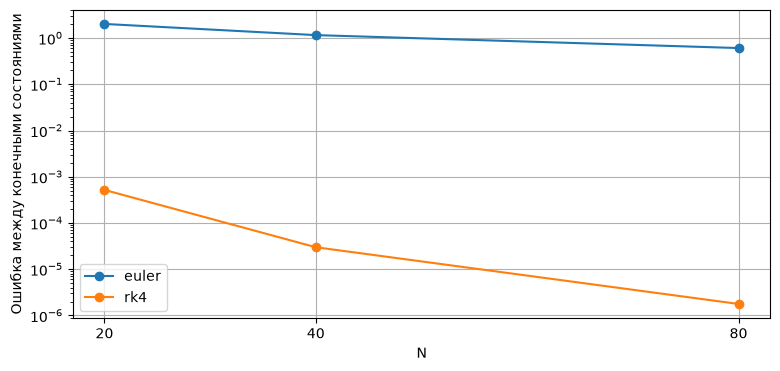

In [40]:
# Ваш эксперимент Euler vs RK4
target = np.array([np.pi, 0.0])
rows = []

for N in [20, 40, 80]:
    for method in ["euler", "rk4"]:
        res = solve_pendulum(N=N, method=method)
        X_check = validate_control(res["U"])

        x_discrete = res["X"][:, -1]
        x_check = X_check[-1]

        rows.append({
            "N": N,
            "method": method,
            "J": res["J"],
            "error_discrete": np.linalg.norm(x_discrete - target),
            "error_validated": np.linalg.norm(x_check - target),
            "error_between": np.linalg.norm(x_discrete - x_check),
            "iterations": res["iterations"],
        })

df = pd.DataFrame(rows)

display(df)

plt.figure(figsize=(9, 4))

for method in ["euler", "rk4"]:
    data = df[df["method"] == method]
    plt.plot(
        data["N"],
        data["error_between"],
        marker="o",
        label=method,
    )

plt.xlabel("N")
plt.ylabel("Ошибка между конечными состояниями")
plt.yscale("log")
plt.xticks([20, 40, 80])
plt.grid()
plt.legend()
plt.show()

<span style="color:red">Вывод:</span>

1. оба метода обеспечивают малую терминальную ошибку дискретной модели, однако при проверке через `solve_ivp` ошибка Euler оказывается значительно больше, чем RK4
2. при увеличении $N$ от 20 до 80 расхождение конечных состояний для Euler уменьшается с $2.016$ до $0.607$, а для RK4 — с $5.19\cdot10^{-4}$ до $1.83\cdot10^{-6}$
3. наблюдаемое уменьшение ошибки согласуется с первым порядком точности Euler и четвёртым порядком RK4
4. значения функционала Euler постепенно приближаются к значениям RK4, которые практически не меняются при измельчении сетки
5. результаты показывают, что для нелинейной задачи оптимального управления RK4 обеспечивает значительно более точное воспроизведение непрерывной динамики, а качество решения необходимо проверять независимым интегрированием исходного ОДУ

## 7. Индивидуальный вариант

Номер варианта определяется номером в списке группы:

- остаток 1 при делении на 3 — **A**;
- остаток 2 — **B**;
- остаток 0 — **C**.

Для варианта используйте RK4 и $N=40$.

Перед запуском напишите 2–3 предложения с прогнозом.

### A. Ограничение скорости

Добавьте
$$
|\omega_k|\le1.
$$

Сравните с базовой задачей:

- $J$;
- terminal error;
- $\max|\omega|$;
- управление;
- фазовую траекторию.

### B. Ограничение на изменение управления

Добавьте
$$
|u_{k+1}-u_k|\le0.05.
$$

Сравните:

- $J$;
- terminal error;
- $\max|u_{k+1}-u_k|$;
- управление.

Объясните, как ограничение меняет форму $u(t)$.

### C. Жёсткое терминальное условие

Замените терминальный штраф на
$$
\theta(T)=\pi,\qquad
\omega(T)=0
$$
и минимизируйте только
$$
0.05\int_0^T u^2(t)\,dt.
$$

Сравните с мягким терминальным штрафом:

- конечное состояние;
- control effort;
- форму управления.

<span style="color:red">Прогноз:</span>

1. жёсткое терминальное условие обеспечит достижение целевого состояния $(\pi, 0)$ в дискретной модели с точностью решателя
2. ожидается увеличение затрат на управление, поскольку теперь нельзя допускать небольшое отклонение от цели ради уменьшения энергии
3. форма оптимального управления может измениться, особенно вблизи конечного момента времени

вариант C

Мягкое условие
x(T) = [3.13993904 0.00562456]
terminal error = 0.005862606543719958
control effort = 2.418161067510645
J = 0.1211209207923147

Жёсткое условие
x(T) = [3.14159265 0.        ]
terminal error = 0.0
control effort = 2.4267692592049963
J = 0.1213384629602498



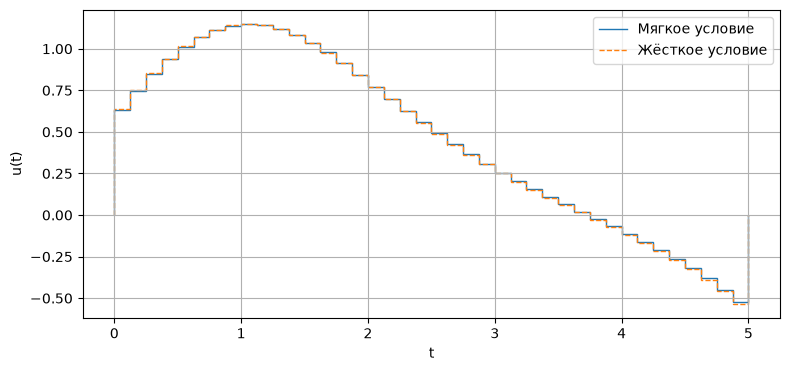

In [41]:
# Ваш индивидуальный вариант
N = 40
T = 5.0
h = T / N

soft = pend_rk4
hard = solve_pendulum(
    N=N,
    method="rk4",
    hard_terminal=True,
)

target = np.array([np.pi, 0.0])

for name, res in [("Мягкое условие", soft), ("Жёсткое условие", hard)]:
    error = np.linalg.norm(res["X"][:, -1] - target)
    effort = h * np.sum(res["U"]**2)

    print(name)
    print("x(T) =", res["X"][:, -1])
    print("terminal error =", error)
    print("control effort =", effort)
    print("J =", res["J"])
    print()

t = np.linspace(0, T, N + 1)

plt.figure(figsize=(9, 4))
plt.stairs(soft["U"], t, label="Мягкое условие")
plt.stairs(hard["U"], t, linestyle="--", label="Жёсткое условие")

plt.xlabel("t")
plt.ylabel("u(t)")
plt.grid()
plt.legend()
plt.show()

<span style="color:red">Вывод:</span>

1. при мягком терминальном штрафе получена ошибка $0.005863$, тогда как жёсткое условие обеспечило точное достижение целевого состояния в дискретной модели
2. энергия управления увеличилась с $2.418161$ до $2.426769$, то есть примерно на $0.36\%$
3. оптимальные управления практически совпадают, различия между ними незначительны
4. жёсткое терминальное условие позволяет исключить отклонение конечного состояния от цели в дискретной задаче ценой небольшого увеличения затрат на управление

# 8. Итог

В конце напишите 10–15 предложений.

Ответьте по существу:

1. Чем direct transcription отличается от подхода из `sem5`, где оптимизировалось только управление?
2. Что в этой работе делает CasADi?
3. Что делает IPOPT?
4. Где в коде находится динамика?
5. Почему ограничения на состояние здесь добавляются удобно?
6. Что показало сравнение Euler и RK4?
7. Что получилось в вашем индивидуальном варианте?
8. В каком месте работы автоматическое дифференцирование CasADi заменило код, который раньше приходилось писать вручную?

## Что сдаётся

Один `.ipynb`.

Перед сдачей:

- `Restart Kernel → Run All`;
- все TODO заполнены;
- таблицы строятся из кода;
- графики подписаны;
- индивидуальный вариант выполнен;
- итоговый текст заполнен.

Если застряли на синтаксисе CasADi, сначала смотрите раздел `Opti stack` в официальной документации:
https://web.casadi.org/docs/

<span style="color:red">Вывод:</span>

В работе были рассмотрены задачи оптимального управления методом direct transcription, при котором одновременно оптимизируются состояния и управления. В отличие от подхода из sem5, где оптимизировалось только управление, здесь состояния непосредственно включены в набор переменных задачи. Динамика системы задаётся равенствами между соседними состояниями, построенными с помощью выбранной схемы интегрирования. Такой подход позволяет удобно добавлять ограничения на состояния непосредственно в задачу оптимизации.

CasADi используется для построения символьных выражений функционала и ограничений, а также автоматического вычисления их производных. IPOPT численно решает полученную нелинейную задачу оптимизации с учётом всех заданных ограничений. Благодаря автоматическому дифференцированию CasADi не требуется вручную реализовывать градиенты функционала и производные динамических ограничений, как в предыдущем подходе.

В задаче двойного интегратора добавление ограничения скорости увеличило значение функционала с $0.0900$ до $0.1188$. При этом оптимальное управление изменилось таким образом, чтобы скорость не превышала заданного предела. Сравнение методов Euler и RK4 показало, что малая терминальная ошибка дискретной модели не гарантирует точного воспроизведения исходной непрерывной динамики. При $N=20$ расхождение конечных состояний составило около $2.016$ для Euler и всего $0.000519$ для RK4. При увеличении $N$ до $80$ ошибки уменьшились примерно до $0.607$ и $0.000002$ соответственно.

В индивидуальном варианте C мягкий терминальный штраф был заменён жёсткими условиями $\theta(T)=\pi$ и $\omega(T)=0$. Это позволило уменьшить терминальную ошибку дискретной модели с $0.005863$ до нуля при небольшом увеличении энергии управления с $2.418161$ до $2.426769$. Таким образом, direct transcription позволяет гибко задавать ограничения и решать задачи оптимального управления, однако точность полученных решений необходимо проверять независимым интегрированием исходной системы.